# Asset-Liability Management: Immunising a Pension Liability

**Goal.** A pension fund or life insurer owes 40 years of payments. When rates fall,
the present value of those payments rises, and the assets must rise by the same amount or
the fund's **surplus** (assets minus liabilities) is wiped out. This project builds four
bond portfolios that hedge the liability and stress them with curve scenarios.

| Strategy | Idea | Tool |
|---|---|---|
| Duration matching | Same PV and duration (barbell 2Y + 40Y) | 2×2 linear system |
| Redington | Same PV and duration, more convexity | 3×3 linear system |
| Key-rate matching | Same sensitivity at each point of the curve | non-negative least squares |
| Cash-flow matching | Cash covers every payment | linear programming |

Amounts are in EUR millions; bonds have a face value of 100.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("alm.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/10-bond-portfolio-immunization")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from alm import (ZeroCurve, liability_cashflows, bond_universe, par_bond_universe, risk_measures, pv, portfolio_flows,
                 match_pv_duration, redington, match_key_rates, cash_flow_matching, key_rate_durations,
                 surplus_change, parallel, twist, butterfly, random_curve_shocks)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
curve = ZeroCurve()
LT, LCF = liability_cashflows()
BT, BCF, MATS = bond_universe()
PILLARS = [2, 5, 10, 15, 20, 30, 40]

## 1. The liability

Payments grow with inflation for 15 years while members retire, then run off. We use
**Fisher-Weil** duration and convexity, computed on the zero curve:
$D = \sum t\,PV_t / PV$ and $C = \sum t^2\,PV_t / PV$.

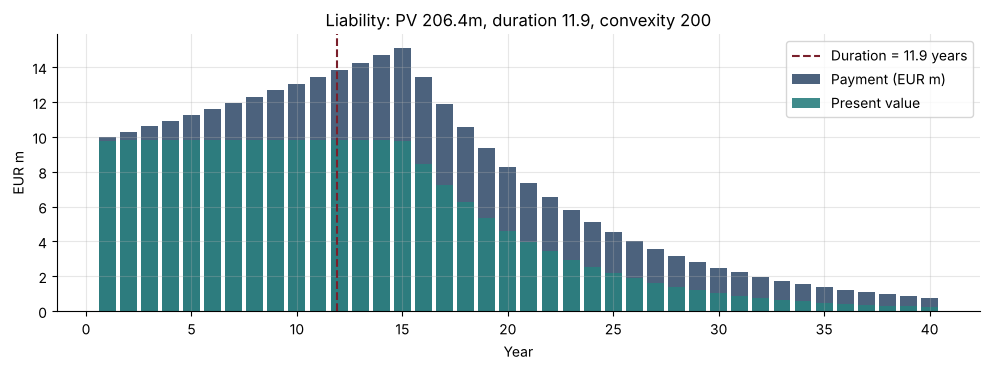

In [2]:
L = risk_measures(LT, LCF, curve)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(LT, LCF, color=NAVY, alpha=0.8, label="Payment (EUR m)")
ax.bar(LT, LCF * curve.df(LT), color=TEAL, alpha=0.9, label="Present value")
ax.axvline(L["duration"], color=BORDEAUX, ls="--", label=f"Duration = {L['duration']:.1f} years")
ax.set(xlabel="Year", ylabel="EUR m", title=f"Liability: PV {L['pv']:.1f}m, duration {L['duration']:.1f}, convexity {L['convexity']:.0f}")
ax.legend(); plt.tight_layout(); plt.savefig("images/liabilities.png", dpi=150); plt.show()

## 2. Four hedging portfolios

The first three strategies use a universe of seven government bonds (2Y to 40Y).
Cash-flow matching needs a bond maturing every year (as with zero-coupon strips), so it
uses a 40-bond par universe; we also show what it would cost with only the seven bonds.

In [3]:
t40, f40, M40 = par_bond_universe(curve)
strategies = {   # name -> (holdings, cash-flow times, bond cash-flow matrix)
    "Duration (2Y + 40Y)": (match_pv_duration(LT, LCF, BT, BCF, curve, (0, 6)), BT, BCF),
    "Redington (2Y + 15Y + 40Y)": (redington(LT, LCF, BT, BCF, curve, (0, 3, 6)), BT, BCF),
    "Key-rate matching": (match_key_rates(LT, LCF, BT, BCF, curve, PILLARS), BT, BCF),
    "Cash-flow matching": (cash_flow_matching(LCF, f40, curve, t40, reinvest=0.02), t40, f40),
}
rows = {}
for name, (w, t, f) in strategies.items():
    rm = risk_measures(t, portfolio_flows(w, f), curve)
    held = sum(w > 1e-9)
    rows[name] = {"Bonds held": held, "PV": rm["pv"], "Duration": rm["duration"], "Convexity": rm["convexity"]}
rows["Liability"] = {"Bonds held": np.nan, "PV": L["pv"], "Duration": L["duration"], "Convexity": L["convexity"]}
table = pd.DataFrame(rows).T
holdings = pd.DataFrame({n: 100 * w for n, (w, t, f) in list(strategies.items())[:3]}, index=[f"{m}Y" for m in MATS]).T
display(holdings.round(1).rename_axis("Face value held (EUR m)"))
table.round(1)

,2Y,5Y,10Y,15Y,20Y,30Y,40Y
Face value held (EUR m),,,,,,,
Duration (2Y + 40Y),108.9,0.0,0.0,0.0,0.0,0.0,86.9
Redington (2Y + 15Y + 40Y),38.2,0.0,0.0,133.2,0.0,0.0,27.2
Key-rate matching,10.4,26.2,42.0,50.5,43.3,21.8,5.2


,Bonds held,PV,Duration,Convexity
Duration (2Y + 40Y),2.0,206.4,11.9,345.0
Redington (2Y + 15Y + 40Y),3.0,206.4,11.9,220.5
Key-rate matching,7.0,206.5,11.8,200.0
Cash-flow matching,40.0,206.4,11.9,200.5
Liability,NaN,206.4,11.9,200.5


In [4]:
w7 = cash_flow_matching(LCF, BCF, curve, BT, reinvest=0.02)
cost7 = pv(BT, portfolio_flows(w7, BCF), curve)
cost40 = pv(t40, portfolio_flows(strategies["Cash-flow matching"][0], f40), curve)
print(f"Cash-flow matching with the 7 bonds would cost {cost7:.1f}m, {cost7 / L['pv'] - 1:.0%} above the liability PV")
print(f"With one bond per year it costs {cost40:.1f}m ({cost40 / L['pv'] - 1:+.2%}): dedication needs a granular universe")

Cash-flow matching with the 7 bonds would cost 322.5m, 56% above the liability PV
With one bond per year it costs 206.4m (+0.00%): dedication needs a granular universe


**Reading the tables.** The barbell matches duration with one very short and one very long
bond, so it carries much **more convexity** than the liability. Redington targets a
convexity just 10% above the liability's. Key-rate matching spreads holdings along the
curve. Cash-flow matching replicates the payments almost exactly, but only with a bond
for every year: with seven bonds it must over-buy to cover the early payments.

## 3. Deterministic curve scenarios

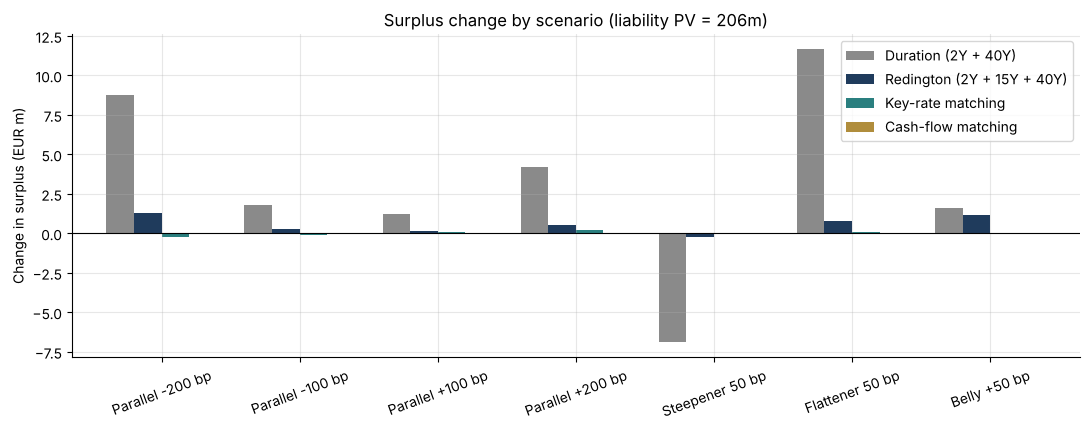

,Duration (2Y + 40Y),Redington (2Y + 15Y + 40Y),Key-rate matching,Cash-flow matching
Parallel -200 bp,8.73,1.29,-0.23,-0.0
Parallel -100 bp,1.80,0.26,-0.12,-0.0
Parallel +100 bp,1.25,0.17,0.11,0.0
Parallel +200 bp,4.18,0.55,0.21,0.0
Steepener 50 bp,-6.90,-0.25,0.03,0.0
Flattener 50 bp,11.67,0.80,0.10,0.0
Belly +50 bp,1.59,1.19,0.00,-0.0


In [5]:
scenarios = {"Parallel -200 bp": parallel(-200), "Parallel -100 bp": parallel(-100), "Parallel +100 bp": parallel(100),
             "Parallel +200 bp": parallel(200), "Steepener 50 bp": twist(50), "Flattener 50 bp": twist(-50),
             "Belly +50 bp": butterfly(50)}
sc = pd.DataFrame({s: {n: surplus_change(w, t, f, LT, LCF, curve, shock) for n, (w, t, f) in strategies.items()}
                   for s, shock in scenarios.items()}).T
ax = sc.plot.bar(figsize=(11, 4.4), color=[GREY, NAVY, TEAL, GOLD], width=0.8)
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("Change in surplus (EUR m)")
ax.set_title("Surplus change by scenario (liability PV = %.0fm)" % L["pv"]); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig("images/scenarios.png", dpi=150); plt.show()
sc.round(2)

- **Parallel moves:** duration matching protects to first order; the extra convexity of
  the barbell and of Redington turns large moves in either direction into gains.
- **Twists:** this is where duration matching fails. A steepener hits the barbell because
  its 40Y bond and the liability do not sit on the same part of the curve. Key-rate
  matching and cash-flow matching stay close to zero.

## 4. Random curve moves: the surplus risk of each strategy

2,000 one-year curve moves drawn from a level / slope / curvature factor model (80, 40 and
20 bp standard deviations), in the spirit of a PCA of euro curve history.

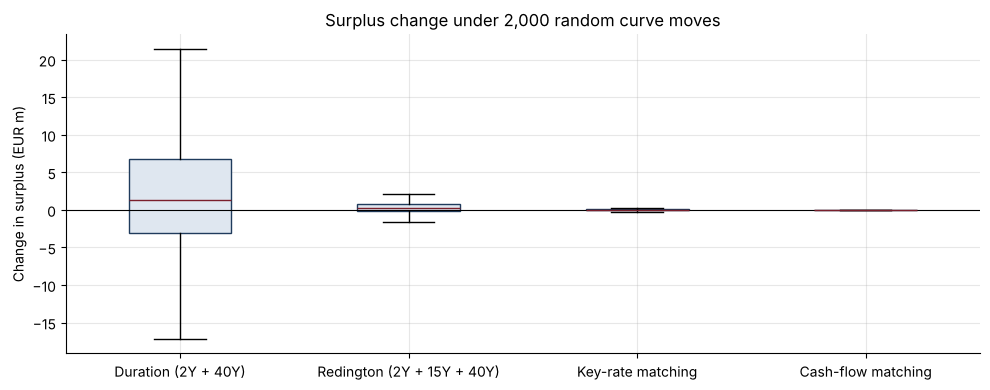

,Std (EUR m),1% worst (EUR m),Std / liability PV
Duration (2Y + 40Y),9.28,-12.03,4.50%
Redington (2Y + 15Y + 40Y),0.94,-1.14,0.45%
Key-rate matching,0.12,-0.24,0.06%
Cash-flow matching,0.00,-0.00,0.00%


In [6]:
shocks = random_curve_shocks(2000, seed=7)
dist = pd.DataFrame({n: [surplus_change(w, t, f, LT, LCF, curve, s) for s in shocks] for n, (w, t, f) in strategies.items()})
summary = pd.DataFrame({"Std (EUR m)": dist.std(), "1% worst (EUR m)": dist.quantile(0.01),
                        "Std / liability PV": dist.std() / L["pv"]})
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([dist[c] for c in dist.columns], tick_labels=dist.columns, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#dfe7f0", color=NAVY), medianprops=dict(color=BORDEAUX))
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("Change in surplus (EUR m)")
ax.set_title("Surplus change under 2,000 random curve moves")
plt.tight_layout(); plt.savefig("images/surplus_risk.png", dpi=150); plt.show()
summary.style.format({"Std (EUR m)": "{:.2f}", "1% worst (EUR m)": "{:.2f}", "Std / liability PV": "{:.2%}"})

## Conclusions
- Matching duration alone leaves the surplus exposed to slope moves: the barbell's
  surplus volatility is about 9m (4.5% of the liability), against 0.9m for Redington and
  0.1m for key-rate matching.
- Key-rate matching with seven bonds gets close to full cash-flow matching, which needs a
  bond for every year and would cost 56% more than the liability with only seven bonds.
- All constraints (PV, duration, convexity, coverage of every payment) are checked in `test_alm.py`.
- **Next steps:** inflation-linked liabilities hedged with inflation swaps, swap overlays
  instead of physical bonds, and a Solvency II interest rate SCR calculation.